<span id="elliptical-curves" data-learnt="2026-11-05" data-topic="My understanding of elliptical curves"></span>My understanding of elliptical curves right now is that elliptical curves are used mainly for generating “random” points in Bitcoin.

The elliptical curve used in Bitcoin is called secp256k1, and it uses this specific equation:

$$
y^2 = x^3 + 7
$$

This is from the more general equation where

$$
y^2 = x^3 + mx + b
$$

m is the slope and b is the intercept of the Y axis, but in this case for Bitcoin $m = 0$ and $b = 7$.

Bitcoin uses elliptical curve with modular arithmetic to create points on the same line. These points are very easy to calculate and generate, but almost impossible to work backwards.

For example, suppose we have a clock, and I started working when the clock is at 11:00 and I finished working when the clock face is at 2:00. Now, no one can guess the amount of time between these two clock faces. It could be 3 hours, or 15 hours, 27 hours etc. This is because the clock automatically uses modulo 12 arithmetic.

Someone could write an algorithm to go through all the possible guesses. To block that, we need to use something where the number of possible answers is almost infinite, or really large. But we also need to represent them in a finite field, so that computers can work on them. Elliptical curves solve these properties. You can easily do addition to generate points using a formula, but it’s hard to find looking back how many times you did the addition to generate the point.

## Exercise by AI — Adding points

For the real-number curve

$$
y^2 = x^3 + 7,
$$

and the two points

$$
P=(0,\sqrt{7}), \qquad Q=(2,\sqrt{15}),
$$

**what is the sum $P+Q$? Solve it using algebra or Python.**

1. Find the slope and the equation of the line through $P$ and $Q$.
2. Find the third crossing point, $R$.
3. Reflect $R$ across the x-axis to find $S=P+Q$.
4. Show your steps or code in **My answer** below. Check your result against the graph.

The graph labels are rounded to three decimal places. Use the square roots above for your calculation.

This exercise uses real numbers. The Bitcoin curve uses $y^2 \equiv x^3 + 7 \pmod p$, where $p=2^{256}-2^{32}-977$. [Source: SEC 2, section 2.4.1](https://www.secg.org/sec2-v2.pdf#page=13)

The graph and graph code below are also by AI.

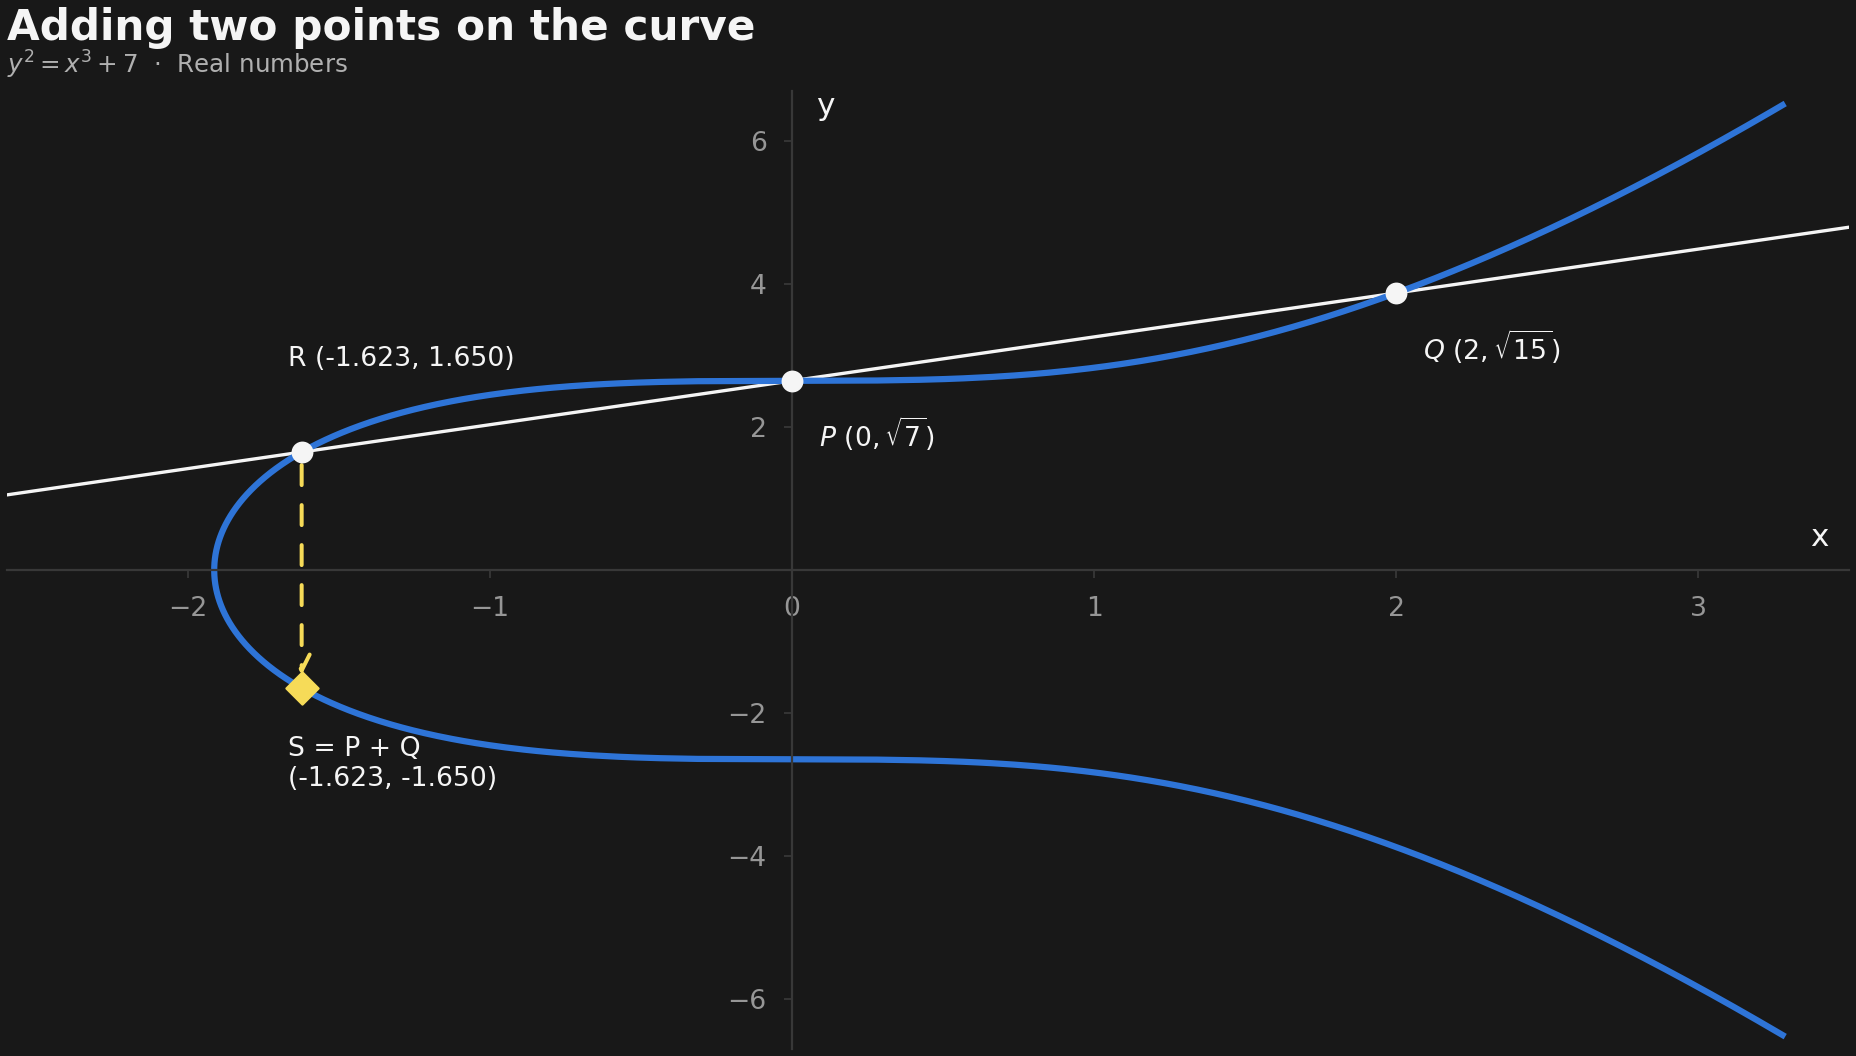

In [1]:
#| code-fold: true
#| code-summary: "Graph code"
# Smooth real-number version of y^2 = x^3 + 7, for algebra practice.
# Bitcoin uses this equation modulo p; this picture uses real numbers.
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display

P = (0.0, np.sqrt(7))
Q = (2.0, np.sqrt(15))

# Find the third crossing R, then reflect it to get S = P + Q.
s = (Q[1] - P[1]) / (Q[0] - P[0])
x_sum = s**2 - P[0] - Q[0]
y_sum = s * (P[0] - x_sum) - P[1]
R = (x_sum, -y_sum)
S = (x_sum, y_sum)

# Using y as the parameter draws both branches and their joining point.
y_curve = np.linspace(-6.5, 6.5, 1301)
x_curve = np.cbrt(y_curve**2 - 7)
x_line = np.linspace(-2.6, 3.5, 500)
y_line = P[1] + s * (x_line - P[0])

with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 12}):
    fig, ax = plt.subplots(figsize=(11.6, 6.6), layout="constrained")
    background = "#181818"
    foreground = "#f5f5f5"
    blue = "#2e74d7"
    yellow = "#f6db58"
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)

    ax.plot(x_curve, y_curve, color=blue, linewidth=2.8, zorder=2)
    ax.plot(x_line, y_line, color=foreground, linewidth=1.5, zorder=1)
    ax.annotate(
        "", xy=(S[0], S[1] + 0.12), xytext=(R[0], R[1] - 0.12),
        arrowprops={"arrowstyle": "->", "color": yellow,
                    "linestyle": (0, (5, 5)), "linewidth": 1.8,
                    "mutation_scale": 18},
        zorder=3,
    )
    ax.scatter(*zip(P, Q, R), s=78, color=foreground, zorder=5)
    ax.scatter(*S, s=105, marker="D", color=yellow, zorder=6)

    labels = [
        (P, r"$P\ (0,\sqrt{7})$", (12, -24)),
        (Q, r"$Q\ (2,\sqrt{15})$", (12, -24)),
        (R, f"R ({R[0]:.3f}, {R[1]:.3f})", (-6, 42)),
        (S, f"S = P + Q\n({S[0]:.3f}, {S[1]:.3f})", (-6, -34)),
    ]
    for point, label, offset in labels:
        ax.annotate(label, point, xytext=offset, textcoords="offset points",
                    color=foreground, ha="left", va="center", zorder=7)

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_position("zero")
        ax.spines[side].set_color("#383838")
        ax.spines[side].set_linewidth(1)
    ax.tick_params(colors="#969696", color="#383838", pad=8)
    ax.set_xticks([-2, -1, 0, 1, 2, 3])
    ax.set_yticks([-6, -4, -2, 2, 4, 6])
    ax.set_xlim(-2.6, 3.5)
    ax.set_ylim(-6.7, 6.7)
    ax.text(3.43, 0.33, "x", color=foreground, ha="right", fontsize=14)
    ax.text(0.08, 6.36, "y", color=foreground, fontsize=14)
    ax.set_title("Adding two points on the curve", loc="left", color=foreground,
                 fontsize=19, fontweight="bold", pad=23)
    ax.text(0.0, 1.01, r"$y^2 = x^3 + 7$  ·  Real numbers",
            transform=ax.transAxes, color="#b0b0b0", fontsize=11, va="bottom")

    picture = BytesIO()
    fig.savefig(picture, format="png", dpi=160, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(data=picture.getvalue(), width=950))


## My answer